## Применение бустинга к задаче Walmart Recruiting

https://www.kaggle.com/competitions/walmart-recruiting-store-sales-forecasting/overview

- EDA смотрите на Kaggle
- Первое место https://www.kaggle.com/competitions/walmart-recruiting-store-sales-forecasting/writeups/david-thaler-first-place-entry Основа: STL, ARIMA, SVD

В этом конкурсе соискателям предоставляются исторические данные о продажах в 45 магазинах Walmart, расположенных в разных регионах. В каждом магазине много отделов, и участники должны спрогнозировать продажи для каждого отдела. В дополнение к этому, в набор данных включены некоторые праздничные скидки. Известно, что эти скидки влияют на продажи, но сложно предсказать, какие отделы пострадают и насколько сильно.

- Данные недельные.
- Прогноз на 39 недель.
- Метрика weighted mean absolute error (WMAE): $$\textrm{WMAE} = \frac{1}{\sum{w_i}} \sum_{i=1}^n w_i | y_i - \hat{y}_i |,$$
где вес равен 5, если неделя праздничная, 1 в противном случае.



<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

Пример сокращённый
- отбор признаков уже выполнен
- хорошие гиперпараметры найдены
- кросс валидации нет
- интервальных оценок нет
- EDA, графиков нет
- анализа самых плохих и самых хороших прогнозов нет
- оценки важности признаков нет

In [5]:
import pandas as pd
import numpy as np
import bottleneck as bn
from numba import jit

from sklearn.preprocessing import LabelEncoder
from functools import reduce
import lightgbm as lgb

In [7]:
# загружаем
train = pd.read_csv('Data/walmart_train.csv')

In [9]:
train

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False
...,...,...,...,...,...
421565,45,98,2012-09-28,508.37,False
421566,45,98,2012-10-05,628.10,False
421567,45,98,2012-10-12,1061.02,False
421568,45,98,2012-10-19,760.01,False


In [11]:
# загружаем
test = pd.read_csv('Data/walmart_test.csv')
test

,Store,Dept,Date,IsHoliday
0,1,1,2012-11-02,False
1,1,1,2012-11-09,False
2,1,1,2012-11-16,False
3,1,1,2012-11-23,True
4,1,1,2012-11-30,False
...,...,...,...,...
115059,45,98,2013-06-28,False
115060,45,98,2013-07-05,False
115061,45,98,2013-07-12,False
115062,45,98,2013-07-19,False


In [13]:
# загружаем
features = pd.read_csv('Data/walmart_features.csv')
features

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8185,45,2013-06-28,76.05,3.639,4842.29,975.03,3.00,2449.97,3169.69,NaN,NaN,False
8186,45,2013-07-05,77.50,3.614,9090.48,2268.58,582.74,5797.47,1514.93,NaN,NaN,False
8187,45,2013-07-12,79.37,3.614,3789.94,1827.31,85.72,744.84,2150.36,NaN,NaN,False
8188,45,2013-07-19,82.84,3.737,2961.49,1047.07,204.19,363.00,1059.46,NaN,NaN,False


In [15]:
features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         8190 non-null   int64  
 1   Date          8190 non-null   object 
 2   Temperature   8190 non-null   float64
 3   Fuel_Price    8190 non-null   float64
 4   MarkDown1     4032 non-null   float64
 5   MarkDown2     2921 non-null   float64
 6   MarkDown3     3613 non-null   float64
 7   MarkDown4     3464 non-null   float64
 8   MarkDown5     4050 non-null   float64
 9   CPI           7605 non-null   float64
 10  Unemployment  7605 non-null   float64
 11  IsHoliday     8190 non-null   bool   
dtypes: bool(1), float64(9), int64(1), object(1)
memory usage: 712.0+ KB



- Рассмотрим упрощенный вариант, без лишних признаков.


In [18]:
# отбираем важные признаки
feat= features[['Store', 'Date', 'Temperature']]

In [20]:
# загружаем данные о размере магазинов
stores = pd.read_csv('Data/walmart_stores.csv')
stores

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875
5,6,A,202505
6,7,B,70713
7,8,A,155078
8,9,B,125833
9,10,B,126512


In [22]:
# пишем функцию слияния датафреймов
def merge_data(train, features, stores):
    train['Date'] = pd.to_datetime(train['Date'])
    features = features.copy()
    features['Date'] = pd.to_datetime(features['Date'])
    df = train.merge(stores, on='Store', how='left')
    df = df.merge(features, on=['Store', 'Date'], how='left')
    df['IsHoliday'] = df['IsHoliday'].astype(int)

    return df

In [24]:
# выполняем слияние
train_data = merge_data(train, feat, stores)
test_data = merge_data(test, feat, stores)

In [26]:
train_data

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature
0,1,1,2010-02-05,24924.50,0,A,151315,42.31
1,1,1,2010-02-12,46039.49,1,A,151315,38.51
2,1,1,2010-02-19,41595.55,0,A,151315,39.93
3,1,1,2010-02-26,19403.54,0,A,151315,46.63
4,1,1,2010-03-05,21827.90,0,A,151315,46.50
...,...,...,...,...,...,...,...,...
421565,45,98,2012-09-28,508.37,0,B,118221,64.88
421566,45,98,2012-10-05,628.10,0,B,118221,64.89
421567,45,98,2012-10-12,1061.02,0,B,118221,54.47
421568,45,98,2012-10-19,760.01,0,B,118221,56.47


In [28]:
test_data

,Store,Dept,Date,IsHoliday,Type,Size,Temperature
0,1,1,2012-11-02,0,A,151315,55.32
1,1,1,2012-11-09,0,A,151315,61.24
2,1,1,2012-11-16,0,A,151315,52.92
3,1,1,2012-11-23,1,A,151315,56.23
4,1,1,2012-11-30,0,A,151315,52.34
...,...,...,...,...,...,...,...
115059,45,98,2013-06-28,0,B,118221,76.05
115060,45,98,2013-07-05,0,B,118221,77.50
115061,45,98,2013-07-12,0,B,118221,79.37
115062,45,98,2013-07-19,0,B,118221,82.84


In [30]:
train.describe()

,Store,Dept,Date,Weekly_Sales
count,421570.000000,421570.000000,421570,421570.000000
mean,22.200546,44.260317,2011-06-18 08:30:31.963375104,15981.258123
min,1.000000,1.000000,2010-02-05 00:00:00,-4988.940000
25%,11.000000,18.000000,2010-10-08 00:00:00,2079.650000
50%,22.000000,37.000000,2011-06-17 00:00:00,7612.030000
75%,33.000000,74.000000,2012-02-24 00:00:00,20205.852500
max,45.000000,99.000000,2012-10-26 00:00:00,693099.360000
std,12.785297,30.492054,NaN,22711.183519



- Делаем преобразование Бокса-Кокса целевой переменной - берем корень четвертой степени.


In [33]:
# преобразование уорнем четвертой степени для целевой переменной
train_data['Weekly_Sales'] = np.abs(train_data['Weekly_Sales']) ** (1/4)

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

Сегменты выбираются по условию конкурса, но в реальных задачах выбор сегмента очень важный этап. Часто заказчик выбирает слишком мелкие сегменты (учитывется слишком много переменных) и нужно отдельно обсуждать этот вопрос. Чем ниже уровень в структуре объектов, тем сложнее строить прогнозы.


In [36]:
# создаем сегменты
train_data['segment'] = (train_data['Store'].astype(str) + '_'
                         + train_data['Dept'].astype(str))
test_data['segment'] = (test_data['Store'].astype(str) + '_'
                         + test_data['Dept'].astype(str))


In [38]:
# сортируем признаки
train_data = train_data.sort_index(axis=1)
train_data

,Date,Dept,IsHoliday,Size,Store,Temperature,Type,Weekly_Sales,segment
0,2010-02-05,1,0,151315,1,42.31,A,12.564830,1_1
1,2010-02-12,1,1,151315,1,38.51,A,14.648145,1_1
2,2010-02-19,1,0,151315,1,39.93,A,14.281102,1_1
3,2010-02-26,1,0,151315,1,46.63,A,11.802398,1_1
4,2010-03-05,1,0,151315,1,46.50,A,12.154945,1_1
...,...,...,...,...,...,...,...,...,...
421565,2012-09-28,98,0,118221,45,64.88,B,4.748375,45_98
421566,2012-10-05,98,0,118221,45,64.89,B,5.006189,45_98
421567,2012-10-12,98,0,118221,45,54.47,B,5.707303,45_98
421568,2012-10-19,98,0,118221,45,56.47,B,5.250550,45_98



- Число уникальных сегментов отличается в train и test.


In [41]:
print(train_data['segment'].nunique())
print(test_data['segment'].nunique())

3331
3169


In [43]:
# множества сегментов
train_segments = set(train_data['segment'])
test_segments = set(test_data['segment'])

# сегменты, которые только в train
missing_in_test = train_segments - test_segments
print("Сегменты только в train", missing_in_test)

# сегменты, которые только в test
missing_in_train = test_segments - train_segments
print("Сегменты только в test", missing_in_train)

Сегменты только в train {'18_78', '3_77', '14_78', '34_78', '32_51', '16_78', '21_96', '11_48', '8_78', '14_77', '11_51', '13_77', '36_71', '3_51', '7_78', '5_77', '21_77', '22_51', '15_77', '32_78', '1_78', '16_51', '29_51', '40_51', '26_51', '16_77', '17_77', '1_51', '45_78', '34_51', '9_97', '2_78', '33_6', '33_35', '28_77', '41_78', '8_51', '5_78', '33_33', '26_50', '34_77', '15_78', '13_51', '43_24', '42_71', '39_47', '11_77', '19_48', '42_34', '21_45', '7_77', '12_77', '27_77', '3_78', '13_78', '20_78', '7_99', '25_77', '25_45', '8_77', '33_36', '24_51', '18_77', '24_77', '25_51', '2_39', '39_51', '21_48', '41_37', '28_43', '33_34', '15_43', '11_78', '36_34', '35_78', '44_34', '12_45', '36_85', '22_78', '3_45', '12_78', '27_39', '6_77', '29_96', '9_93', '29_78', '22_48', '20_51', '17_51', '21_50', '14_45', '9_78', '19_51', '5_51', '19_45', '29_77', '29_45', '2_51', '36_29', '30_41', '19_78', '19_77', '25_96', '1_77', '6_51', '10_77', '41_51', '11_50', '39_78', '23_51', '45_51', '

In [45]:
# оставляем в train_data только сегменты, которые есть в тесте
train_data = train_data[train_data['segment'].isin(test_segments)]
print(train_data['segment'].nunique())

3158



- сегменты имеют разную длину, поэтому ниже в таблице сегмент/дата появятся пропуски.


In [48]:
# группировка по segment и посчет уникальных дат
date_counts = train_data.groupby('segment')['Date'].nunique().reset_index()

In [50]:
# переименовываем столбец с количеством дат
date_counts.rename(columns={'Date': 'num_dates'}, inplace=True)

In [52]:
# сортируем по возрастанию num_dates
date_counts = date_counts.sort_values(by='num_dates', ascending=True)
date_counts.head(20)

,segment,num_dates
1096,23_99,1
1851,33_71,1
2570,43_55,1
2072,36_99,1
585,17_99,1
1532,29_99,1
512,16_99,1
2758,4_39,1
2195,38_99,1
396,15_37,1


In [54]:
# разворачиваем строки переменной segment обучающего набора
# в столбцы, значениями столбцов будут зависимой переменной sales

pivot_train_data = train_data.pivot_table(index='Date',
                                          columns='segment',
                                          values='Weekly_Sales')
pivot_train_data

segment,10_1,10_10,10_11,10_12,10_13,10_14,10_16,10_17,10_18,10_19,...,9_85,9_87,9_9,9_90,9_91,9_92,9_94,9_95,9_96,9_98
Date,,,,,,,,,,,,,,,,,,,,,
2010-02-05,14.160911,14.803804,13.841495,10.090236,16.494464,15.316434,12.660759,13.857175,9.716214,7.975641,...,5.132389,10.396074,9.226020,6.952076,4.136028,10.382510,NaN,12.353845,7.026871,NaN
2010-02-12,16.130435,14.997831,13.274665,9.840014,16.215892,15.040022,12.518115,13.656565,12.956007,7.747435,...,4.670692,10.001137,8.998607,7.061275,4.831114,10.259822,5.598648,12.222521,6.928271,NaN
2010-02-19,14.934635,15.042392,13.500974,10.248786,16.151933,14.879006,13.510845,13.629949,11.289486,7.755551,...,5.409997,9.929314,9.243755,7.037382,4.538455,10.057868,6.820273,11.993965,6.640185,NaN
2010-02-26,13.539068,14.955643,13.079816,10.254819,16.353241,14.940739,12.909467,13.287809,5.501784,8.053901,...,5.125124,9.426570,9.402013,6.989400,4.657188,10.191059,NaN,12.148282,7.016378,NaN
2010-03-05,13.828927,14.945418,13.368008,10.248825,16.281974,14.713447,13.700002,13.492675,6.145619,7.758588,...,5.014199,9.995900,10.132563,6.976566,5.105550,10.281906,NaN,12.204709,7.134747,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2012-09-28,13.319872,14.787840,12.379153,9.637970,15.448731,13.220154,11.484840,12.304022,10.257317,7.357757,...,5.906179,10.830558,11.254630,7.495669,5.621937,11.636235,NaN,13.490317,7.832305,NaN
2012-10-05,13.805377,14.685576,12.752483,9.852611,15.963501,13.624127,11.282530,12.606599,11.273429,7.381231,...,5.284164,11.668287,11.425977,7.372699,5.461548,11.982139,3.550877,13.696292,8.100827,NaN
2012-10-12,14.197186,14.854110,12.627448,9.754011,15.719852,13.576251,10.665385,12.510325,11.779180,7.658901,...,4.915670,11.145208,10.844483,7.492319,5.141554,11.934321,1.403486,13.382407,7.786523,NaN



- Всего у нас 3158 временных рядов с длиной 143 точки, но некоторые ряды имеют всего по одному значению. Не будем усложнять и искать оптимальный вариант. Просто сделаем линейную интерполяцию в обе стороны для заполнения пропусков.


In [57]:
# количество пропусков по столбцам
nan_counts = pivot_train_data.isna().sum()
nan_counts

segment
10_1       0
10_10      0
10_11      0
10_12      0
10_13      0
        ... 
9_92       0
9_94      69
9_95       0
9_96       0
9_98     129
Length: 3158, dtype: int64

In [59]:
# смотрим общее количество пропусков
pivot_train_data.isna().sum().sum()

32386

In [61]:
# выполняем линейную интерполяцию в оба направления
pivot_train_data = pivot_train_data.interpolate(method='linear',
                                                axis=0,
                                                limit_direction='both')

In [63]:
pivot_train_data.isna().sum().sum()

0

In [65]:
# задаем список сегментов
segments_list = pivot_train_data.columns.tolist()

In [67]:
HORIZON = 39

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

- Нам нужно избежать утечек - подглядывание в будущее при создании новых признаков.
- Утечки зависят от стратегии прогнозирования.
- При рекурсии нужно каждый раз строить признаки на тест заново.
- При прямой (direct) стратегии прогнозирования признаки вычисляются сразу для всей тестовой выборки.
- Можно комбинировать прогнозы, построенных для разных стратегий прогнозирования. Эта идея реализована в библиотеке tsururu https://github.com/sb-ai-lab/tsururu

<div class="admonition note" name="html-admonition" style="background: rgba(255,145,0,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #ff9100; border-color: #ff9100; padding-left: 10px; padding-right: 10px">

<p class="title">
    <i style="font-size: 18px; color:#ff9100; border-color: #ff1744;"></i>
    <b style="color: #ff9100;"> <span style="color: #ff9100;">&#9888;</span> Warning</b>
</p>

При рекурсии нужно создавать новый набор признаков и заново искать лучшие гиперпараметры.


Тестовая выборка начинается с 2012-11-02. Напишем функцию, которая удлинняет датасет так, чтобы можно было начать с конкретного дня недели


In [71]:
# удлиняем индекс на длину горизонта
def plus_horizon_2(data, horizon, freq):
    """
    Дополняет датафрейм новыми строками на `horizon` шагов вперёд с указанной частотой.
    Поддерживает недельные частоты: 'W', 'W-MON', ..., 'W-SUN'.
    Все не-дата столбцы заполняются NaN.
    """
    weekday_map = {
        'MON': 0,
        'TUE': 1,
        'WED': 2,
        'THU': 3,
        'FRI': 4,
        'SAT': 5,
        'SUN': 6
    }

    # Определяем, где дата
    if isinstance(data.index, pd.DatetimeIndex):
        df = data.copy()
    else:
        date_col = data.columns[0]
        if not pd.api.types.is_datetime64_any_dtype(data[date_col]):
            raise ValueError("Первый столбец должен быть датой (datetime).")
        df = data.copy().set_index(date_col)

    df = df.sort_index()
    last_date = df.index[-1]

    # Обработка недель с указанием дня
    if freq.startswith('W-') and len(freq) > 1:
        day_abbr = freq.split('-', 1)[1].upper()
        if day_abbr not in weekday_map:
            raise ValueError(f"Недопустимый день в частоте: {freq}. "
                             f"Используйте: {list(weekday_map.keys())}")
        weekday_num = weekday_map[day_abbr]
        offset = pd.offsets.Week(weekday=weekday_num)

        # Начинаем поиск с дня, следующего за последней датой
        start = last_date + pd.Timedelta(days=1)
        first_new = offset.rollforward(start)

        # Генерируем horizon дат
        new_dates = [first_new + i * offset for i in range(horizon)]
        new_dates = pd.DatetimeIndex(new_dates)

    else:
        # Обычная частота
        try:
            new_dates = pd.date_range(
                start=last_date,
                periods=horizon + 1,
                freq=freq,
                inclusive='right'  # исключает last_date
            )
        except Exception as e:
            raise ValueError(f"Ошибка при генерации дат с частотой '{freq}': {e}")

    # Создаём новые строки с NaN
    new_rows = pd.DataFrame(
        index=new_dates,
        columns=df.columns,
        dtype='object'
    )

    # Объединяем
    result = pd.concat([df, new_rows])

    # Восстанавливаем структуру, если дата была столбцом
    if not isinstance(data.index, pd.DatetimeIndex):
        result = result.reset_index().rename(columns={'index': data.columns[0]})

    return result

In [73]:
long_pivot_train_data = plus_horizon_2(pivot_train_data, horizon=HORIZON, freq='W-FRI')
long_pivot_train_data.tail(HORIZON+1)

C:\Users\dmpla\AppData\Local\Temp\ipykernel_31524\8040761.py:67: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result = pd.concat([df, new_rows])


segment,10_1,10_10,10_11,10_12,10_13,10_14,10_16,10_17,10_18,10_19,...,9_85,9_87,9_9,9_90,9_91,9_92,9_94,9_95,9_96,9_98
2012-10-26,15.546101,14.453195,12.630306,9.751783,15.716319,13.362657,10.33244,12.546801,12.868975,7.562594,...,4.936168,10.543923,10.884249,7.459801,5.499666,11.632518,3.907044,13.414549,8.302805,1.565085
2012-11-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-11-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-11-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-11-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-11-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-12-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-12-14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-12-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-12-28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [75]:
# создаем зависимую переменную из пропусков
test_data['Weekly_Sales'] = np.NaN
# сортируем признаки, чтобы при объединении датасетов не было ошибок
test_data = test_data.sort_index(axis=1)
test_data

,Date,Dept,IsHoliday,Size,Store,Temperature,Type,Weekly_Sales,segment
0,2012-11-02,1,0,151315,1,55.32,A,NaN,1_1
1,2012-11-09,1,0,151315,1,61.24,A,NaN,1_1
2,2012-11-16,1,0,151315,1,52.92,A,NaN,1_1
3,2012-11-23,1,1,151315,1,56.23,A,NaN,1_1
4,2012-11-30,1,0,151315,1,52.34,A,NaN,1_1
...,...,...,...,...,...,...,...,...,...
115059,2013-06-28,98,0,118221,45,76.05,B,NaN,45_98
115060,2013-07-05,98,0,118221,45,77.50,B,NaN,45_98
115061,2013-07-12,98,0,118221,45,79.37,B,NaN,45_98
115062,2013-07-19,98,0,118221,45,82.84,B,NaN,45_98


In [77]:
# объединяем исторический набор и 
# набор новых данных  по оси строк
data = pd.concat([train_data, test_data], axis=0)
data

,Date,Dept,IsHoliday,Size,Store,Temperature,Type,Weekly_Sales,segment
0,2010-02-05,1,0,151315,1,42.31,A,12.564830,1_1
1,2010-02-12,1,1,151315,1,38.51,A,14.648145,1_1
2,2010-02-19,1,0,151315,1,39.93,A,14.281102,1_1
3,2010-02-26,1,0,151315,1,46.63,A,11.802398,1_1
4,2010-03-05,1,0,151315,1,46.50,A,12.154945,1_1
...,...,...,...,...,...,...,...,...,...
115059,2013-06-28,98,0,118221,45,76.05,B,NaN,45_98
115060,2013-07-05,98,0,118221,45,77.50,B,NaN,45_98
115061,2013-07-12,98,0,118221,45,79.37,B,NaN,45_98
115062,2013-07-19,98,0,118221,45,82.84,B,NaN,45_98


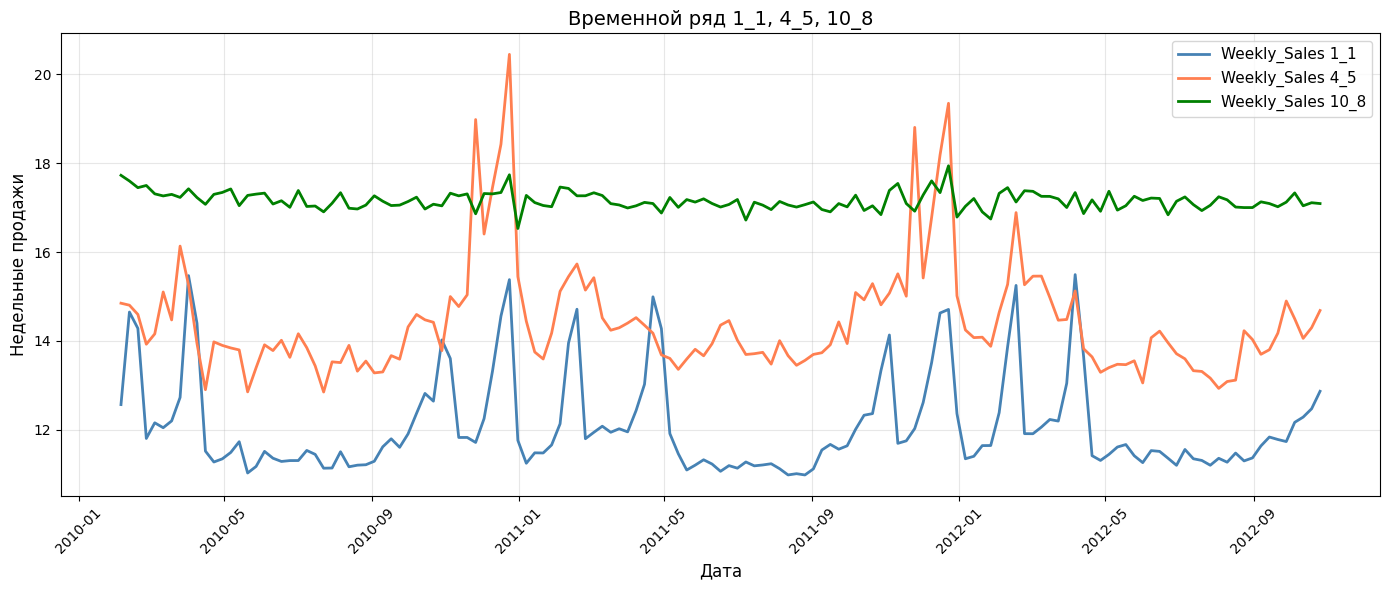

In [81]:
import matplotlib.pyplot as plt

# Выбираем один временной ряд для визуализации (например, первый встречающийся segment)
sample_segment_1 = data['segment'].iloc[0]  # или задать явно, например: '1_1'
sample_segment_2 = '4_5'
sample_segment_3 = '10_8'

# Фильтруем данные для выбранного segment и сортируем по дате
TS_1 = data[data['segment'] == sample_segment_1].sort_values('Date').copy()
TS_2 = data[data['segment'] == sample_segment_2].sort_values('Date').copy()
TS_3 = data[data['segment'] == sample_segment_3].sort_values('Date').copy()

# Строим график
plt.figure(figsize=(14, 6))

# 
plt.plot(TS_1['Date'], TS_1['Weekly_Sales'],
         label='Weekly_Sales 1_1', color='steelblue', linewidth=2)

plt.plot(TS_2['Date'], TS_2['Weekly_Sales'],
         label='Weekly_Sales 4_5', color='coral', linewidth=2)

plt.plot(TS_2['Date'], TS_3['Weekly_Sales'],
         label='Weekly_Sales 10_8', color='green', linewidth=2)

# Оформление
plt.title(f'Временной ряд {sample_segment_1}, {sample_segment_2}, {sample_segment_3}', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Недельные продажи', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Новые признаки

In [76]:
# создаем календарные признаки
data['day_of_month'] = data['Date'].dt.day
data['day_of_year'] = data['Date'].dt.dayofyear
data['month'] = data['Date'].dt.month
data['quarter'] = data['Date'].dt.quarter
data['week_of_year'] = data['Date'].dt.isocalendar().week
data['year_end'] = data['Date'].dt.is_year_end
data['qrt_start'] = data['Date'].dt.is_quarter_start
data['qrt_end'] = data['Date'].dt.is_quarter_end
data['month_start'] = data['Date'].dt.is_month_start
data['month_end'] = data['Date'].dt.is_month_end


In [78]:
# признак взаимодействия сегмента и недели
data['segment_week_of_year'] = data['segment'].astype(str) + '_' + data['week_of_year'].astype(str)

Этот признак кодирует уникальную комбинацию: "магазин + отдел + неделя года".

- Продажи разных сегментов (Store_Dept) ведут себя по-разному в разные недели года:
  В отделе игрушек — пик в неделю перед Рождеством.
  В отделе школьных принадлежностей — пик в августе (back-to-school).
  В отделе садового инвентаря — пик весной.
- Без этого признака модель не может понять, что "неделя 50" для одного сегмента — это праздник, а для другого — обычный спад.пад.
👉 Таким обра`зом, segment_week_of`_year фиксирует сезонность на уровне конкретного сегмента, а не глоба
и.льно.

Как модель использует такой признак?
- Дерево может сделать сплит: if segment_week_of_year == "12_34_50": predict high sales
- Это эквивалентно запоминанию среднего значения продаж для этой комбинации.

Другие полезные признаки взаимодействия
- Сезонность + сегмент: учитывает, что весна для отдела одежды ≠ весна для отдела отопления.
- Праздник + сегмент: некоторые отделы (игрушки, электроника) резко растут в праздники, другие — нет.
- Месяц + сегмент: более грубая, но стабильная альтернатива `week_of_year`.
- Тип магазина + неделя: если у вас мало данных по конкретному Store_Dept, можно обобщить до типа магазина (A, B, C).
- Размер магазина + сезон: большие магазины могут иметь другой сезонный профиль.
- Неделя в месяце + сегмент: полезно для акций, привязанных к началу/концу месяца.

<div class="admonition note" name="html-admonition" style="background: rgba(255,145,0,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #ff9100; padding-left: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#ff9100; border-color: #ff1744;"></i>
    <b style="color: #ff9100;">⚠ Warning</b>
</p>

Признаки вроде `segment_week_of_year` создают десятки тысяч уникальных категорий.

Это нормально для градиентного бустинга, потому что:
- Он не делает one-hot encoding
- Он строит сплиты по частоте/целевой переменной
- Он регуляризован (lambda_l2, min_gain_to_split)
Но если данных мало — лучше использовать более грубые взаимодействия (например, `type_week` вместо `segment_week`).

</div>

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

### Бустинг может найти взаимодействия сам?

Градиентный бустинг строит последовательность деревьев, и каждое дерево может:
- Сделать сплит по признаку A
- Затем по признаку B внутри одной из веток
- Это эквивалентно моделированию взаимодействия A × B
 
Таким образом, взаимодействия низкого порядка (2–3 признака) деревья действительно могут обнаружить самостоятельно, особенно если:
- Данных достаточно.
- Взаимодействие стабильно и сильно влияет на целевую переменную.

❌ Но есть критические ограничения
1. Высокий порядок взаимодействий — недостижим

Дерево глубиной `max_depth=6` может захватить максимум 6-факторное взаимодействие, но:
- Вероятность, что оно найдёт конкретную комбинацию (например, Store=12 & Dept=34 & week_of_year=50) — мала, если данных мало.
- А в Walmart таких уникальных комбинаций десятки тысяч.

Пример:
Чтобы выучить `segment_week_of_year = "12_34_50"`, дереву нужно сделать 3 последовательных сплита:
- Store == 12 → Dept == 34 → week_of_year == 50.

Это требует глубины ≥ 3 только на эту комбинацию, а у вас ещё сотни других сегментов!

2. Разреженные категории — проблема
   
Если какая-то комбинация встречается редко (например, новый магазин), дерево не сможет её выучить, потому что не хватит листьев или наблюдений.

А вот явный признак `segment_week_of_year` сразу даёт модели сигнал:
- «Все наблюдения с этим ID — одна группа».
- Модель может применить усреднение по группе, даже если внутри группы всего 2–3 точки.

3. Эффективность обучения
   
Когда вы создаёте явный признак взаимодействия:
- Модели не нужно тратить деревья/листья на его поиск
- Она быстрее сходится
- Требуется меньше `n_estimators`

#### Эмпирические наблюдения

- В задачах вроде Walmart, Store Item Demand, Rossmann — явные interaction features (`store_item_month`, `dept_holiday`, и т.д.) стабильно улучшают скор.
- В LightGBM/XGBoost часто используют `categorical_feature` именно для таких составных ключей.
- В Py-Boost (GPU-only) это ещё важнее, потому что GPU эффективен при большом количестве простых операций + явные признаки → меньше глубина → больше параллелизм

#### Когда можно не создавать interaction features?

- Признаки непрерывные и взаимодействие гладкое (например, price × discount).
- Много данных, и вы используете глубокие деревья (max_depth ≥ 8).
- Вы делаете feature selection и хотите минимизировать размерность.стьсть

In [80]:
# пишем функцию для создания переменной - сезон
def get_season(month):
    if (month > 11 or month < 3):
        return 0
    elif (month == 3 or month <= 5):
        return 1
    elif (month >=6 and month < 9):
        return 2
    else:
        return 3

In [82]:
data['season'] = data['month'].apply(lambda x: get_season(x))
data['year'] = data['Date'].dt.year

In [84]:
# объединяем индикаторы начала года, квартала, месяца в дополнительный признак
data['start_sum'] = (
    data['Date'].dt.is_year_start.astype(int)
    + data['Date'].dt.is_quarter_start.astype(int)
    + data['Date'].dt.is_month_start.astype(int)
)

In [86]:
# объединяем  индикаторы конца года, квартала, месяца в дополнительный признак
data['end_sum'] = (
    data['Date'].dt.is_year_end.astype(int)
    + data['Date'].dt.is_quarter_end.astype(int)
    + data['Date'].dt.is_month_start.astype(int)
)


- гармоники


In [88]:
data['day_of_month_sin'] = np.sin(2 * np.pi * data['day_of_month'] / 31)
data['day_of_month_cos'] = np.cos(2 * np.pi * data['day_of_month'] / 31)

In [90]:
data['day_of_year_sin'] = np.sin(2 * np.pi * data['day_of_year'] / 366)
data['day_of_year_cos'] = np.cos(2 * np.pi * data['day_of_year'] / 366)

In [92]:
data['month_sin'] = np.sin(2 * np.pi * data['month'] / 12)
data['month_cos'] = np.cos(2 * np.pi * data['month'] / 12)

In [94]:
data['quarter_sin'] = np.sin(2 * np.pi * data['quarter'] / 4)
data['quarter_of_month_cos'] = np.cos(2 * np.pi * data['quarter'] / 4)

In [96]:
data['week_of_year_sin'] = np.sin(2 * np.pi * data['week_of_year'] / 52)
data['week_of_year_cos'] = np.cos(2 * np.pi * data['week_of_year'] / 52)


- ещё пара календарных


In [98]:
# номер декады в году
data['decade_of_year'] = ((data['day_of_year'] - 1) // 10) + 1

In [100]:
# порядковый номер календарной недели внутри месяца
data['week_of_motnh'] = (
    data["week_of_year"] -
    data.groupby(data['month'])["week_of_year"].transform("min") +1
)

In [102]:
data

,Date,Dept,IsHoliday,Size,Store,Temperature,Type,Weekly_Sales,segment,day_of_month,...,day_of_year_sin,day_of_year_cos,month_sin,month_cos,quarter_sin,quarter_of_month_cos,week_of_year_sin,week_of_year_cos,decade_of_year,week_of_motnh
0,2010-02-05,1,0,151315,1,42.31,A,12.564830,1_1,5,...,0.579421,0.815028,8.660254e-01,5.000000e-01,1.000000e+00,6.123234e-17,0.568065,0.822984,4,1
1,2010-02-12,1,1,151315,1,38.51,A,14.648145,1_1,12,...,0.672949,0.739689,8.660254e-01,5.000000e-01,1.000000e+00,6.123234e-17,0.663123,0.748511,5,2
2,2010-02-19,1,0,151315,1,39.93,A,14.281102,1_1,19,...,0.756771,0.653680,8.660254e-01,5.000000e-01,1.000000e+00,6.123234e-17,0.748511,0.663123,5,3
3,2010-02-26,1,0,151315,1,46.63,A,11.802398,1_1,26,...,0.829677,0.558244,8.660254e-01,5.000000e-01,1.000000e+00,6.123234e-17,0.822984,0.568065,6,4
4,2010-03-05,1,0,151315,1,46.50,A,12.154945,1_1,5,...,0.890617,0.454755,1.000000e+00,6.123234e-17,1.000000e+00,6.123234e-17,0.885456,0.464723,7,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115059,2013-06-28,98,0,118221,45,76.05,B,NaN,45_98,28,...,0.068615,-0.997643,1.224647e-16,-1.000000e+00,1.224647e-16,-1.000000e+00,-0.0,-1.0,18,5
115060,2013-07-05,98,0,118221,45,77.50,B,NaN,45_98,5,...,-0.051479,-0.998674,-5.000000e-01,-8.660254e-01,-1.000000e+00,-1.836970e-16,-0.120537,-0.992709,19,2
115061,2013-07-12,98,0,118221,45,79.37,B,NaN,45_98,12,...,-0.170830,-0.985301,-5.000000e-01,-8.660254e-01,-1.000000e+00,-1.836970e-16,-0.239316,-0.970942,20,3
115062,2013-07-19,98,0,118221,45,82.84,B,NaN,45_98,19,...,-0.287717,-0.957716,-5.000000e-01,-8.660254e-01,-1.000000e+00,-1.836970e-16,-0.354605,-0.935016,20,4


In [104]:
# меняем строки на числа в переменной Type
mapping = {'A': 0, 'B': 1, 'C': 2}
data['Type'] = data['Type'].map(mapping)

### Скользящие статистики

In [106]:
# создаем и обрабатываем все датафреймы

# начинаем с исходного датафрейма
# (он уже содержит базовые признаки)

processed_dfs = [data]

# === СКОЛЬЗЯЩИЕ СРЕДНИЕ ===

# перебираем все размеры окон
for window in [39, 50, 60, 70, 80]:
    # делаем копию исходного датасета
    df = long_pivot_train_data.copy()
    # для каждого сегмента (товара/категории)
    for segment in segments_list:
        # сдвигаем значения на 1 (чтобы не использовать текущий день)
        # и применяем функцию скользящего среднего (bn.move_mean)
        df[segment] = df[[segment]].shift(1).apply(
            lambda x: bn.move_mean(x, window=window, min_count=1)
        )

    # преобразуем таблицу обратно в "длинный" формат
    melted_df = (
        # переносим индекс в колонку
        df.reset_index()
        # переименовываем колонку индекса в Date
        .rename(columns={'index': 'Date'})
        # делаем unpivot
        .melt(
            # дата остается фиксированным столбцом
            id_vars = 'Date',
            # название сегмента
            var_name = 'segment',
            # значение признака
            value_name = f'sales_rolling_mean{window}'
        )
    )
    # добавляем результат в список датафреймов
    processed_dfs.append(melted_df)

# === СКОЛЬЗЯЩИЕ МЕДИАНЫ ===

# перебираем все размеры окон
for window in [39, 50, 60, 70, 80]:
    # делаем копию исходного датасета
    df = long_pivot_train_data.copy()
      # для каждого сегмента (товара/категории)
    for segment in segments_list:
        # сдвигаем значения на 1 (чтобы не использовать текущий день)
        # и применяем функцию скользящего среднего (bn.move_mean)
        df[segment] = df[[segment]].shift(1).apply(
            lambda x: bn.move_median(x, window=window, min_count=1)
        )

    # преобразуем таблицу обратно в "длинный" формат
    melted_df = (
        # переносим индекс в колонку
        df.reset_index()
        # переименовываем колонку индекса в Date
        .rename(columns={'index': 'Date'})
        # делаем unpivot
        .melt(
            # дата остается фиксированным столбцом
            id_vars = 'Date',
            # название сегмента
            var_name = 'segment',
            # значение признака
            value_name = f'sales_rolling_median{window}'
        )
    )
    # добавляем результат в список датафреймов
    processed_dfs.append(melted_df)

# === СКОЛЬЗЯЩИЕ РАЗНОСТИ ===

# перебираем все размеры окон
for window in [41, 85]:
    # делаем копию исходного датасета
    df = long_pivot_train_data.copy()
    # для каждого сегмента (товара/категории)
    for segment in segments_list:
        # сдвигаем значения на 50 
        shifted_series = df[segment].shift(50)
        # вычисляем скользящую разность (по модулю)
        df[segment] = (
            shifted_series.rolling(window=window, min_periods=1)
                            .agg(lambda w: abs(w.iloc[-1] - w.iloc[0]))
        )

    # преобразуем таблицу обратно в "длинный" формат
    melted_df = (
        # переносим индекс в колонку
        df.reset_index()
        # переименовываем колонку индекса в Date
        .rename(columns={'index': 'Date'})
        # делаем unpivot
        .melt(
            # дата остается фиксированным столбцом
            id_vars = 'Date',
            # название сегмента
            var_name = 'segment',
            # значение признака
            value_name = f'sales_rolling_diff{window}'
        )
    )
    # добавляем результат в список датафреймов
    processed_dfs.append(melted_df)

In [107]:
# функция для создания групповых скользящих статистик по годам
def groupby_moving_stats(df, by, target, min_periods=1, 
                         window=4, aggfunc='mean', 
                         offset=False, start_date=None): 
    """
    Создает групповые скользящие статистики.
    
    Параметры
    ----------
    df: pandas.DataFrame
        Датафрейм Pandas, наблюдения, приходящиеся 
        на историческую (обучающую) часть, должны 
        быть отсортированы по категориям
        группирующей переменной.
    by: string
        Имя группирующего столбца.
    target: string
        Имя агрегируемого столбца.
    min_periods: int, по умолчанию 1    
        Минимальное количество наблюдений в окне для
        вычисления скользящих статистик.
    window: int, по умолчанию 4
        Ширина окна.
    aggfunc: string, по умолчанию 'mean'
        Агрегирующая функция.    
    offset: bool, по умолчанию True
        Вычисляет групповые скользящие 
        статистики со смещением по времени.
    start_date: datetime
        Стартовая дата для смещения.  
    """ 
    if offset:
        df = df[df.index >= start_date]

    # если не является списком
    if type(by) != list:
        # превращаем в список
        by = [by]
        
    df = df.groupby(by)[target].transform(
        lambda x: x.shift(1).rolling(
            window=window, 
            min_periods=min_periods).agg(aggfunc))
    
    df.fillna(0, inplace=True)
    return df

In [119]:
@jit(nopython=True)
def rolling_stats_numba(values, window, min_periods, aggfunc):
    """
    Универсальная функция для различных скользящих статистик.
    
    aggfunc: 'median', 'mean', 'std', 'min', 'max', 'sum'
    """
    n = len(values)
    result = np.full(n, 0.0)
    
    for i in range(1, n):  # начинаем с 1 из-за shift(1)
        start = max(0, i - window)
        end = i
        window_data = values[start:end]
        
        if len(window_data) >= min_periods:
            if aggfunc == 'median':
                result[i] = np.median(window_data)
            elif aggfunc == 'mean':
                result[i] = np.mean(window_data)
            elif aggfunc == 'std':
                result[i] = np.std(window_data)
            elif aggfunc == 'min':
                result[i] = np.min(window_data)
            elif aggfunc == 'max':
                result[i] = np.max(window_data)
            elif aggfunc == 'sum':
                result[i] = np.sum(window_data)
    
    return result

In [108]:
def groupby_moving_stats_numba(df, by, target, min_periods=1, 
                               window=4, aggfunc='median', 
                               offset=False, start_date=None):
    """Компактная версия с использованием numba для ускорения."""
    
    if offset and start_date is None:
        raise ValueError("Задайте стартовую дату или отключите смещение.")
    
    if offset:
        df = df[df.index >= start_date]
    
    if not isinstance(by, list):
        by = [by]
    
    # поддерживаемые numba-функции
    supported_funcs = {'median', 'mean', 'std', 'min', 'max', 'sum'}
    
    if aggfunc in supported_funcs:
        result = (df.groupby(by)[target]
                  .apply(lambda x: pd.Series(
                      rolling_stats_numba(x.values, window, min_periods, aggfunc),
                      index=x.index)))
        
        if hasattr(result, 'droplevel'):
            result = result.droplevel(0)
        
        return result.fillna(0)
    
    # для неподдерживаемых функций используем pandas
    return (df.groupby(by, group_keys=False)[target]
            .apply(lambda x: x.shift(1)
                            .rolling(window=window, min_periods=min_periods)
                            .agg(aggfunc))
            .fillna(0))



In [121]:
# === ГРУППОВЫЕ СКОЛЬЗЯЩИЕ МЕДИАНЫ ===

# перебираем все размеры окон
for window in [39, 50, 60, 70, 80]:
    # делаем копию исходного датасета
    df = long_pivot_train_data.copy()
    # извлекаем номер недели из индекса (даты)
    df['week'] = df.index.isocalendar().week
    # для каждого сегмента (товара/категории)
    for segment in segments_list:
        # считаем групповую скользящую медиану по неделям
        df[segment] = groupby_moving_stats_numba(
            df, 'week', segment, window=window, aggfunc='median'
        )
    # преобразуем таблицу обратно в "длинный формат"
    melted_df = (
        # переносим индекс в колонку
        df.reset_index()
        # переименовываем колонку индекса в Date
        .rename(columns={'index': 'Date'})
        # делаем unpivot
        .melt(
            # дата остается фиксированным столбцом
            id_vars = 'Date',
            # название сегмента
            var_name = 'segment',
            # значение признака
            value_name = f'sales_grp_roll_median{window}'
        )
    )
    # добавляем результат в список датафреймов
    processed_dfs.append(melted_df)

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

Далее вычисляются групповые скользящие медианы — полезный инструмент при прогнозировании рядов продаж, особенно в условиях высокой волатильности, выбросов или пропущенных значений. 

1. Робастность к выбросам
- Продажи часто содержат такие выбросы, и медиана лучше отражает «типичный» уровень спроса за последние `window` недель.
2. Учёт сезонности по неделям года
  - Для каждой недели года вычисляется медиана продаж по этой же неделе в предыдущих годах в окне из `window` недель. Обратите внимание: `window` здесь — не количество недель подряд, а количество лет × 52 недели, сгруппированных по week. Например, `window=104` - данные за последние 2 года по неделям.
- Это даёт долгосрочную недельную сезонность: «Как обычно продавали в эту же неделю в прошлые годы?» Модель учится, что, например, в неделю 51 — всегда рост (предпраздничный), а в неделю 1 — спад.
3. Сглаживание шума при сохранении структуры
  - медиана в скользящем окне убирает случайные колебания, но сохраняет уровень тренда и сезонности, если окно выбрано правильно.
  - особенно полезно, когда данные разреженные (много нулей или пропусков) — медиана игнорирует их лучше, чем среднее.
4. Группировка по сегментам (товары/категории/магазины)
  - Каждый товар/категория имеет свою динамику и сезонность.
  - Групповая медиана по week внутри сегмента учитывает специфику именно этого товара.
5. Многоуровневый контекст через разные окна
  - `window=2` (2 года) — более чувствителен к недавним изменениям.
  - `window=5` (5 лет) — устойчивее к краткосрочным колебаниям, лучше отражает долгосрочную сезонность.
  - далее модель (например, LightGBM, CatBoost) будет сама решать, какой горизонт важнее для прогноза.

Если вы добавите такие признаки в модель, они часто значительно улучшают точность, особенно для:
- товаров с выраженной годовой сезонностью (например, ёлки в декабре, кондиционеры летом),
- прогнозов на несколько недель вперёд,
- данных с шумом и аномалиями.

In [123]:
# === СКОЛЬЗЯЩИЕ МЕДИАНЫ ПО ГОДАМ===

# перебираем все размеры окон
for window in [2, 3, 4, 5]:
    # делаем копию исходного датасета
    df = long_pivot_train_data.copy()
    # извлекаем номер недели из индекса (даты)
    df['week'] = df.index.isocalendar().week
    # для каждого сегмента (товара/категории)
    for segment in segments_list:
        # считаем групповую скользящую медиану по неделям
        df[segment] = groupby_moving_stats(df, 'week', segment,
                         window=window, aggfunc='median'
        )

    # преобразуем таблицу обратно в "длинный" формат
    melted_df = (
        # переносим индекс в колонку
        df.reset_index()
        # переименовываем колонку индекса в Date
        .rename(columns={'index': 'Date'})
        # делаем unpivot
        .melt(
            # дата остается фиксированным столбцом
            id_vars = 'Date',
            # название сегмента
            var_name = 'segment',
            # значение признака
            value_name = f'sales_grp_roll_median_year{window}'
        )
    )
    # добавляем результат в список датафреймов
    processed_dfs.append(melted_df)


In [124]:
# === ОБЪЕДИНЕНИЕ ВСЕХ ПРИЗНАКОВ ===

# последовательно объединяем все датафреймы из processed_dfs
data = reduce(
    # джойним по двум ключам: segment + Date
    # how='left' - оставляем все строки из левого датафрейма
    lambda left, right: pd.merge(
        left, right, how='left', on=['segment', 'Date']
    ),
    processed_dfs
)

In [127]:
data

,Date,Dept,IsHoliday,Size,Store,Temperature,Type,Weekly_Sales,segment,day_of_month,...,sales_rolling_diff85,sales_grp_roll_median39,sales_grp_roll_median50,sales_grp_roll_median60,sales_grp_roll_median70,sales_grp_roll_median80,sales_grp_roll_median_year2,sales_grp_roll_median_year3,sales_grp_roll_median_year4,sales_grp_roll_median_year5
0,2010-02-05,1,0,151315,1,42.31,0,12.564830,1_1,5,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2010-02-12,1,1,151315,1,38.51,0,14.648145,1_1,12,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2010-02-19,1,0,151315,1,39.93,0,14.281102,1_1,19,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2010-02-26,1,0,151315,1,46.63,0,11.802398,1_1,26,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2010-03-05,1,0,151315,1,46.50,0,12.154945,1_1,5,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
534267,2013-06-28,98,0,118221,45,76.05,1,NaN,45_98,28,...,0.811474,5.126183,5.126183,5.126183,5.126183,5.126183,5.378992,5.126183,5.126183,5.126183
534268,2013-07-05,98,0,118221,45,77.50,1,NaN,45_98,5,...,0.312055,5.067904,5.067904,5.067904,5.067904,5.067904,5.360956,5.067904,5.067904,5.067904
534269,2013-07-12,98,0,118221,45,79.37,1,NaN,45_98,12,...,1.201927,5.134865,5.134865,5.134865,5.134865,5.134865,5.40215,5.134865,5.134865,5.134865
534270,2013-07-19,98,0,118221,45,82.84,1,NaN,45_98,19,...,0.905061,4.979332,4.979332,4.979332,4.979332,4.979332,5.185684,4.979332,4.979332,4.979332


In [129]:
# убедимся, что сохранена исходная сортировка
data = data.sort_values(['Store', 'Dept', 'Date'])
data

,Date,Dept,IsHoliday,Size,Store,Temperature,Type,Weekly_Sales,segment,day_of_month,...,sales_rolling_diff85,sales_grp_roll_median39,sales_grp_roll_median50,sales_grp_roll_median60,sales_grp_roll_median70,sales_grp_roll_median80,sales_grp_roll_median_year2,sales_grp_roll_median_year3,sales_grp_roll_median_year4,sales_grp_roll_median_year5
0,2010-02-05,1,0,151315,1,42.31,0,12.564830,1_1,5,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2010-02-12,1,1,151315,1,38.51,0,14.648145,1_1,12,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2010-02-19,1,0,151315,1,39.93,0,14.281102,1_1,19,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2010-02-26,1,0,151315,1,46.63,0,11.802398,1_1,26,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2010-03-05,1,0,151315,1,46.50,0,12.154945,1_1,5,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
534267,2013-06-28,98,0,118221,45,76.05,1,NaN,45_98,28,...,0.811474,5.126183,5.126183,5.126183,5.126183,5.126183,5.378992,5.126183,5.126183,5.126183
534268,2013-07-05,98,0,118221,45,77.50,1,NaN,45_98,5,...,0.312055,5.067904,5.067904,5.067904,5.067904,5.067904,5.360956,5.067904,5.067904,5.067904
534269,2013-07-12,98,0,118221,45,79.37,1,NaN,45_98,12,...,1.201927,5.134865,5.134865,5.134865,5.134865,5.134865,5.40215,5.134865,5.134865,5.134865
534270,2013-07-19,98,0,118221,45,82.84,1,NaN,45_98,19,...,0.905061,4.979332,4.979332,4.979332,4.979332,4.979332,5.185684,4.979332,4.979332,4.979332


<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

Почему нет лаговых признаков? Горизонт большой, плохо работают. Лаги работают при горизонтах менее 30, а лучше до 14.
При больших горизонтах главное правильно смоделировать сезонность через гармоники и скользящие статистики. 

Учет тренда, конечно тоже важен.

Наверняка есть и другие полезные признаки, которые мы не нашли.

### Обучение

In [131]:
# разбиваем данные обратно на исторический набор и набр новых данных
data = data.fillna(0)
hist_data = data[data['Date'] < '2012-11-02']
new_data = data[data['Date'] >= '2012-11-02']

In [133]:
hist_data

,Date,Dept,IsHoliday,Size,Store,Temperature,Type,Weekly_Sales,segment,day_of_month,...,sales_rolling_diff85,sales_grp_roll_median39,sales_grp_roll_median50,sales_grp_roll_median60,sales_grp_roll_median70,sales_grp_roll_median80,sales_grp_roll_median_year2,sales_grp_roll_median_year3,sales_grp_roll_median_year4,sales_grp_roll_median_year5
0,2010-02-05,1,0,151315,1,42.31,0,12.564830,1_1,5,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2010-02-12,1,1,151315,1,38.51,0,14.648145,1_1,12,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2010-02-19,1,0,151315,1,39.93,0,14.281102,1_1,19,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2010-02-26,1,0,151315,1,46.63,0,11.802398,1_1,26,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2010-03-05,1,0,151315,1,46.50,0,12.154945,1_1,5,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
419203,2012-09-28,98,0,118221,45,64.88,1,4.748375,45_98,28,...,4.161870,4.126394,4.126394,4.126394,4.126394,4.126394,4.126394,4.126394,4.126394,4.126394
419204,2012-10-05,98,0,118221,45,64.89,1,5.006189,45_98,5,...,3.630444,4.478683,4.478683,4.478683,4.478683,4.478683,4.478683,4.478683,4.478683,4.478683
419205,2012-10-12,98,0,118221,45,54.47,1,5.707303,45_98,12,...,3.598735,4.547206,4.547206,4.547206,4.547206,4.547206,4.547206,4.547206,4.547206,4.547206
419206,2012-10-19,98,0,118221,45,56.47,1,5.250550,45_98,19,...,2.849438,4.90023,4.90023,4.90023,4.90023,4.90023,4.90023,4.90023,4.90023,4.90023


In [135]:
new_data

,Date,Dept,IsHoliday,Size,Store,Temperature,Type,Weekly_Sales,segment,day_of_month,...,sales_rolling_diff85,sales_grp_roll_median39,sales_grp_roll_median50,sales_grp_roll_median60,sales_grp_roll_median70,sales_grp_roll_median80,sales_grp_roll_median_year2,sales_grp_roll_median_year3,sales_grp_roll_median_year4,sales_grp_roll_median_year5
419208,2012-11-02,1,0,151315,1,55.32,0,0.0,1_1,2,...,2.648512,13.867452,13.867452,13.867452,13.867452,13.867452,13.867452,13.867452,13.867452,13.867452
419209,2012-11-09,1,0,151315,1,61.24,0,0.0,1_1,9,...,0.507743,11.758403,11.758403,11.758403,11.758403,11.758403,11.758403,11.758403,11.758403,11.758403
419210,2012-11-16,1,0,151315,1,52.92,0,0.0,1_1,16,...,1.338795,11.786701,11.786701,11.786701,11.786701,11.786701,11.786701,11.786701,11.786701,11.786701
419211,2012-11-23,1,1,151315,1,56.23,0,0.0,1_1,23,...,2.166090,11.868981,11.868981,11.868981,11.868981,11.868981,11.868981,11.868981,11.868981,11.868981
419212,2012-11-30,1,0,151315,1,52.34,0,0.0,1_1,30,...,3.139438,12.430457,12.430457,12.430457,12.430457,12.430457,12.430457,12.430457,12.430457,12.430457
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
534267,2013-06-28,98,0,118221,45,76.05,1,0.0,45_98,28,...,0.811474,5.126183,5.126183,5.126183,5.126183,5.126183,5.378992,5.126183,5.126183,5.126183
534268,2013-07-05,98,0,118221,45,77.50,1,0.0,45_98,5,...,0.312055,5.067904,5.067904,5.067904,5.067904,5.067904,5.360956,5.067904,5.067904,5.067904
534269,2013-07-12,98,0,118221,45,79.37,1,0.0,45_98,12,...,1.201927,5.134865,5.134865,5.134865,5.134865,5.134865,5.40215,5.134865,5.134865,5.134865
534270,2013-07-19,98,0,118221,45,82.84,1,0.0,45_98,19,...,0.905061,4.979332,4.979332,4.979332,4.979332,4.979332,5.185684,4.979332,4.979332,4.979332


In [137]:
# формируем исторический набо меток
y_hist_data = hist_data['Weekly_Sales']
# удаляем из исторического набора данных даты и продажи
hist_data_init = hist_data.copy()
hist_data = hist_data.drop(['Date', 'Weekly_Sales'], axis=1)
# удаляем из набора новых данных даты и продажи
new_data_init = new_data.copy()
new_data = new_data.drop(['Date', 'Weekly_Sales'], axis=1)

In [139]:
# проверяем еше раз пропуски
print(hist_data.isnull().sum())
print('')
print(new_data.isnull().sum())

Dept                           0
IsHoliday                      0
Size                           0
Store                          0
Temperature                    0
Type                           0
segment                        0
day_of_month                   0
day_of_year                    0
month                          0
quarter                        0
week_of_year                   0
year_end                       0
qrt_start                      0
qrt_end                        0
month_start                    0
month_end                      0
segment_week_of_year           0
season                         0
year                           0
start_sum                      0
end_sum                        0
day_of_month_sin               0
day_of_month_cos               0
day_of_year_sin                0
day_of_year_cos                0
month_sin                      0
month_cos                      0
quarter_sin                    0
quarter_of_month_cos           0
week_of_ye

In [141]:
# смотрим на типы всех переменных
hist_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 419208 entries, 0 to 419207
Data columns (total 55 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Dept                         419208 non-null  int64  
 1   IsHoliday                    419208 non-null  int32  
 2   Size                         419208 non-null  int64  
 3   Store                        419208 non-null  int64  
 4   Temperature                  419208 non-null  float64
 5   Type                         419208 non-null  int64  
 6   segment                      419208 non-null  object 
 7   day_of_month                 419208 non-null  int32  
 8   day_of_year                  419208 non-null  int32  
 9   month                        419208 non-null  int32  
 10  quarter                      419208 non-null  int32  
 11  week_of_year                 419208 non-null  UInt32 
 12  year_end                     419208 non-null  bool   
 13  qrt_

In [143]:
new_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 115064 entries, 419208 to 534271
Data columns (total 55 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Dept                         115064 non-null  int64  
 1   IsHoliday                    115064 non-null  int32  
 2   Size                         115064 non-null  int64  
 3   Store                        115064 non-null  int64  
 4   Temperature                  115064 non-null  float64
 5   Type                         115064 non-null  int64  
 6   segment                      115064 non-null  object 
 7   day_of_month                 115064 non-null  int32  
 8   day_of_year                  115064 non-null  int32  
 9   month                        115064 non-null  int32  
 10  quarter                      115064 non-null  int32  
 11  week_of_year                 115064 non-null  UInt32 
 12  year_end                     115064 non-null  bool   
 13 

In [145]:
# создаем энкодер
le = LabelEncoder()

for col in ['segment', 'segment_week_of_year']:
    # обучаем на обоих датафреймах
    all_values = pd.concat([hist_data[col], new_data[col]])
    le.fit(all_values)
    # применяем к обоим датасетам
    hist_data[col] = le.transform(hist_data[col])
    new_data[col] = le.transform(new_data[col])

In [147]:
# присвоим тип category
for col in ['Dept', 'Store']:
    hist_data[col] = hist_data[col].astype('category')
    new_data[col] = new_data[col].astype('category')

In [149]:
# Обучаем бустинг l1
lgbm_full_model = lgb.LGBMRegressor(
    objective='regression_l1',
    n_estimators=2000,
    learning_rate=0.15,
    num_leaves=42,
    random_state=42,
    feature_fraction=0.85,
    n_jobs=1,
    verbose=-1
)

In [151]:
lgbm_full_model.fit(hist_data, y_hist_data,
                    categorical_feature=['Dept', 'Store']);

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

- не забываем про обратное преобразование
- делаем обрезку отрицательных прогнозов

In [153]:
# получаем прогнозы для новых данных
lgbm_predictions = np.clip(lgbm_full_model.predict(new_data) ** 4, 0, None)
new_data_init['lgbm_predictions'] = pd.Series(lgbm_predictions,
                                              index=new_data_init.index)

In [155]:
# формируем файл для проверки на сайте Kaggle
submission = new_data_init[['Store', 'Dept', 'Date']].copy()
submission['Weekly_Sales'] = new_data_init['lgbm_predictions']
submission['ID'] = submission['Store'].astype(str) + '_' + \
                   submission['Dept'].astype(str) + '_' + \
                   submission['Date'].dt.strftime('%Y-%m-%d')
submission = submission[['ID', 'Weekly_Sales']]
submission.to_csv('Data/walmart_submission.csv', index=False)

In [157]:
# Обучаем бустинг l2
lgbm_full_model2 = lgb.LGBMRegressor(
    objective='regression_l2',
    n_estimators=2000,
    learning_rate=0.15,
    num_leaves=41,
    random_state=82,
    feature_fraction=0.88,
    n_jobs=1,
    verbose=-1
)

In [159]:
lgbm_full_model2.fit(hist_data, y_hist_data,
                    categorical_feature=['Dept', 'Store']);

In [162]:
# получаем прогнозы для новых данных
lgbm_predictions2 = np.clip(lgbm_full_model2.predict(new_data) ** 4, 0, None)
new_data_init['lgbm_predictions2'] = pd.Series(lgbm_predictions2,
                                              index=new_data_init.index)

In [163]:
submission['Weekly_Sales'] = new_data_init['lgbm_predictions2']
submission.to_csv('Data/walmart_submission2.csv', index=False)


- делаем взвешенную комбинацию двух прогнозов


In [166]:
# усредняем прогнозы
new_data_init['lgbm_predictions_ensemble'] = (
    new_data_init['lgbm_predictions'] *0.96 +
    new_data_init['lgbm_predictions2']
) / 2

In [168]:
submission['Weekly_Sales'] = new_data_init['lgbm_predictions_ensemble']
submission.to_csv('Data/walmart_submission_ensemble.csv', index=False)

<b> Private Score = 2478.32 — на 9-е место </b>

<b> Public Score = 2340.86 </b>

### Коррекция прогнозов

Получаются плохие прогнозы для двух последних недель года, которые приходятся на Рождествои и перед Новым годом. Кроме того, метрика настроена так, что ошибка прогноза в праздничную неделю умножается на 5.

💡 Идея: если в 51-ю неделю прогнозируются аномально высокие продажи по сравнению с тем, что обычно бывает в 52-ю неделю (например, перед Рождеством), возможно, это завышенная оценка — и её нужно снизить. Если условие выполнено, то уменьшаем прогноз на 15% (оставляем 85% от исходного значения).

💡 Для 52-й недели: хотя обычно после пика (51-я неделя) продажи падают, слишком резкое падение может быть нереалистичным.
Например, в некоторых категориях (подарочные карты, товары с доставкой) продажи остаются высокими и в 52-ю неделю.

«Прогноз в 52-ю неделю настолько мал, что даже если его увеличить на 65% (умножить на 1.65), он всё равно меньше, чем типичные продажи в 51-й неделе».  Если условие выполнено, то увеличиваем прогноз на 50% (умножаем на 1.5).

In [170]:
tmp = new_data_init.copy()

# Вычисление медиан
# Здесь также стоит попробовать использовать реальные Weekly_Sales 
# из обучающих данных для расчёта median_51 и median_52 вместо lgbm_predictions
median_51 = tmp[tmp.week_of_year == 51].groupby(['Store', 'Dept'])['lgbm_predictions'].median()
median_52 = tmp[tmp.week_of_year == 52].groupby(['Store', 'Dept'])['lgbm_predictions'].median()

# Присваивание медиан обратно в tmp
tmp['median_51'] = tmp.set_index(['Store', 'Dept']).index.map(median_51)
tmp['median_52'] = tmp.set_index(['Store', 'Dept']).index.map(median_52)

pred = tmp['lgbm_predictions'].copy()  # остаётся Series

mask51 = tmp.week_of_year == 51
mask52 = tmp.week_of_year == 52

pred.loc[mask51] = np.where(
    pred.loc[mask51] > 1.5 * tmp.loc[mask51, 'median_52'],
    pred.loc[mask51] * 0.85,
    pred.loc[mask51]
)

pred.loc[mask52] = np.where(
    pred.loc[mask52] * 1.65 < tmp.loc[mask52, 'median_51'],
    pred.loc[mask52] * 1.5,
    pred.loc[mask52]
)

pred = pred.values

new_data_init['lgbm_predictions_corr'] = pred

submission['Weekly_Sales'] = new_data_init['lgbm_predictions_corr']
submission.to_csv('Data/walmart_submission_corr.csv', index=False)


#### Private Score = 2439.25 — на 7-е место

#### Public Score = 2334.80


In [174]:
tmp = new_data_init.copy()

# Вычисление медиан
median_51 = tmp[tmp.week_of_year == 51].groupby(['Store', 'Dept'])['lgbm_predictions'].median()
median_52 = tmp[tmp.week_of_year == 52].groupby(['Store', 'Dept'])['lgbm_predictions'].median()

# Присваивание медиан обратно в tmp
tmp['median_51'] = tmp.set_index(['Store', 'Dept']).index.map(median_51)
tmp['median_52'] = tmp.set_index(['Store', 'Dept']).index.map(median_52)


pred = tmp['lgbm_predictions2'].copy()  # остаётся Series

mask51 = tmp.week_of_year == 51
mask52 = tmp.week_of_year == 52

# Корректировка для недели 51
pred.loc[mask51] = np.where(
    pred.loc[mask51] > 1.5 * tmp.loc[mask51, 'median_52'],
    pred.loc[mask51] * 0.85,
    pred.loc[mask51]
)

# Корректировка для недели 52
pred.loc[mask52] = np.where(
    pred.loc[mask52] * 1.65 < tmp.loc[mask52, 'median_51'],
    pred.loc[mask52] * 1.5,
    pred.loc[mask52]
)

# В конце, если нужен массив:
pred = pred.values

new_data_init['lgbm_predictions_corr2'] = pred

submission['Weekly_Sales'] = new_data_init['lgbm_predictions_corr']
submission.to_csv('Data/walmart_submission_corr2.csv', index=False)

In [176]:
# усредняем скорректированные прогнозы прогнозы
new_data_init['lgbm_predictions_ensemble_corr'] = (
    new_data_init['lgbm_predictions_corr'] *0.96 +
    new_data_init['lgbm_predictions_corr2']
) / 2

In [178]:
submission['Weekly_Sales'] = new_data_init['lgbm_predictions_ensemble_corr']
submission.to_csv('Data/walmart_submission_ensemble_corr.csv', index=False)

<b> Private Score = 2347.93 — на 2-е место </b>

<b> Public Score = 2229.15 </b>

Для первого места нужно менее 2301.48. Основное улучшение можно получить за счёт глобальных расстояний до праздников (глобальные, а не в пределах года). Почему работало? Помогало бустингу лучше улавливать тренд. Также некоторое улучшение даст дополнительный отбор признаков.